# Forecast — audit du jeu de données

Ce notebook valide et explore des transactions pseudonymisées, puis construit les exemples de prévision résiduelle. Il n'entraîne, ne compare et ne sélectionne aucun modèle.

In [2]:
from collections import Counter
from dataclasses import asdict
from datetime import date
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from forecast_ml.dataset_builder import build_training_dataset
from forecast_ml.eligibility import exclusion_reason
from forecast_ml.validation import read_raw_csv

project_root = Path.cwd().resolve()
if not (project_root / 'pyproject.toml').exists():
    project_root = project_root.parent
if not (project_root / 'pyproject.toml').exists():
    raise RuntimeError('Run Jupyter from the ml-pipeline directory')

raw_path = Path(os.getenv('FORECAST_RAW_DATA', 'data/raw/synthetic_transactions.csv'))
if not raw_path.is_absolute():
    raw_path = project_root / raw_path
as_of_date = date.fromisoformat(os.getenv('FORECAST_AS_OF_DATE', date.today().isoformat()))
print(f'Input: {raw_path}')
print(f'Dataset as-of date: {as_of_date}')

Input: C:\Users\aziza\Desktop\stage ete 2026\project\smart-financial-wellness\ml-pipeline\data\raw\synthetic_transactions.csv
Dataset as-of date: 2026-01-01


## 1. Validation du contrat et de la confidentialité

Le chargement échoue immédiatement si l'en-tête, une valeur monétaire, une date ou un champ d'éligibilité est invalide. Le fichier doit rester dans `data/raw/`, qui est ignoré par Git.

In [3]:
transactions = read_raw_csv(raw_path)
raw_frame = pd.read_csv(raw_path, dtype=str, keep_default_na=False)
print(f'Validated rows: {len(transactions):,}')
raw_frame.head()

Validated rows: 1,642


,profile_key,account_key,booking_date,known_date,amount,direction,currency,source,provider_status,is_internal_transfer,category_code
0,profile_0001,account_0001_checking,2024-01-03,2024-01-03,4776.0600,CREDIT,TND,BANK_SYNC,POSTED,false,INCOME_SALARY
1,profile_0001,account_0001_checking,2024-01-03,2024-01-03,80.7300,DEBIT,TND,MANUAL,,false,TRANSPORT
2,profile_0001,account_0001_checking,2024-01-05,2024-01-05,606.2400,DEBIT,TND,BANK_SYNC,POSTED,false,HOUSING
3,profile_0001,account_0001_checking,2024-01-06,2024-01-06,125.5600,DEBIT,TND,FILE_IMPORT,,false,SHOPPING
4,profile_0001,account_0001_checking,2024-01-07,2024-01-07,121.1800,DEBIT,TND,FILE_IMPORT,,false,LEISURE


In [4]:
coverage = pd.Series({
    'rows': len(transactions),
    'profiles': raw_frame['profile_key'].nunique(),
    'accounts': raw_frame['account_key'].nunique(),
    'first_booking_date': raw_frame['booking_date'].min(),
    'last_booking_date': raw_frame['booking_date'].max(),
    'first_known_date': raw_frame['known_date'].min(),
    'last_known_date': raw_frame['known_date'].max(),
})
coverage.to_frame('value')

,value
rows,1642
profiles,5
accounts,10
first_booking_date,2024-01-01
last_booking_date,2025-12-27
first_known_date,2024-01-02
last_known_date,2025-12-27


In [5]:
display(raw_frame['currency'].value_counts().rename('rows').to_frame())
display(raw_frame['source'].value_counts().rename('rows').to_frame())
display(raw_frame['provider_status'].replace('', '<blank>').value_counts().rename('rows').to_frame())

,rows
currency,
TND,1642


,rows
source,
BANK_SYNC,858
FILE_IMPORT,467
MANUAL,317


,rows
provider_status,
<blank>,784
POSTED,765
PENDING,49
REVERSED,44


In [6]:
exclusions = Counter(exclusion_reason(row).value for row in transactions)
display(pd.Series(exclusions, name='rows').sort_index().to_frame())

missing_summary = raw_frame.replace('', pd.NA).isna().sum()
display(missing_summary.rename('missing_rows').to_frame())

,rows
BANK_NOT_POSTED,93
ELIGIBLE,1447
INTERNAL_TRANSFER,102


,missing_rows
profile_key,0
account_key,0
booking_date,0
known_date,0
amount,0
direction,0
currency,0
source,0
provider_status,784
is_internal_transfer,0


### Mes observations — données brutes

- TODO : la couverture temporelle est-elle suffisante par profil et devise ? : all profiles have the same booking_date & known_date for each transaction
- TODO : les répartitions des sources et statuts ressemblent-elles aux données attendues ? : i think so
- TODO : vérifier que `known_date` représente bien la première disponibilité dans l'application. : how and why
- TODO : noter toute anomalie sans supprimer de ligne silencieusement. : provider_status <blank> 784 / all currencies are TND : currency TND	1642


## 2. Construction des exemples sans fuite

Les caractéristiques utilisent uniquement les transactions connues au cutoff. Les résultats réels après cutoff servent exclusivement aux colonnes de résultat et à `residual_target`.

In [7]:
examples = build_training_dataset(transactions, as_of_date=as_of_date)
processed_frame = pd.DataFrame(asdict(example) for example in examples)
if processed_frame.empty:
    raise ValueError('No completed target month exists before FORECAST_AS_OF_DATE')
print(f'Processed examples: {len(processed_frame):,}')
processed_frame.head()

Processed examples: 600


,dataset_version,profile_key,currency,target_month,cutoff_date,calendar_month,cutoff_day,days_remaining,month_to_date_credit,month_to_date_debit,...,historical_remaining_net_flow_range,deterministic_remaining_income,deterministic_remaining_expense,deterministic_remaining_net_flow,usable_history_count,deterministic_fallback_reason,actual_remaining_income,actual_remaining_expense,actual_remaining_net_flow,residual_target
0,forecast-residual-v1,profile_0001,TND,2024-01,2024-01-05,1,5,26,4776.0600,686.9700,...,0.0000,0.0000,0.0000,0.0000,0,NO_USABLE_HISTORY,625.9800,1234.5300,-608.5500,-608.5500
1,forecast-residual-v1,profile_0001,TND,2024-01,2024-01-10,1,10,21,4776.0600,1189.0500,...,0.0000,0.0000,0.0000,0.0000,0,NO_USABLE_HISTORY,625.9800,732.4500,-106.4700,-106.4700
2,forecast-residual-v1,profile_0001,TND,2024-01,2024-01-15,1,15,16,4776.0600,1434.6500,...,0.0000,0.0000,0.0000,0.0000,0,NO_USABLE_HISTORY,625.9800,486.8500,139.1300,139.1300
3,forecast-residual-v1,profile_0001,TND,2024-01,2024-01-20,1,20,11,4776.0600,1624.3000,...,0.0000,0.0000,0.0000,0.0000,0,NO_USABLE_HISTORY,625.9800,297.2000,328.7800,328.7800
4,forecast-residual-v1,profile_0001,TND,2024-01,2024-01-25,1,25,6,5402.0400,1761.2300,...,0.0000,0.0000,0.0000,0.0000,0,NO_USABLE_HISTORY,0.0000,160.2700,-160.2700,-160.2700


In [8]:
display(
    processed_frame.groupby(['profile_key', 'currency']).size()
    .rename('rows').to_frame()
)
display(pd.crosstab(processed_frame['target_month'], processed_frame['cutoff_day']))

,,rows
profile_key,currency,
profile_0001,TND,120
profile_0002,TND,120
profile_0003,TND,120
profile_0004,TND,120
profile_0005,TND,120


cutoff_day,5,10,15,20,25
target_month,,,,,
2024-01,5,5,5,5,5
2024-02,5,5,5,5,5
2024-03,5,5,5,5,5
2024-04,5,5,5,5,5
2024-05,5,5,5,5,5
2024-06,5,5,5,5,5
2024-07,5,5,5,5,5
2024-08,5,5,5,5,5
2024-09,5,5,5,5,5


In [9]:
display(processed_frame['usable_history_count'].value_counts().sort_index().rename('rows').to_frame())
display(processed_frame['deterministic_fallback_reason'].value_counts().rename('rows').to_frame())

,rows
usable_history_count,
0,25
1,25
2,25
3,25
4,25
5,25
6,450


,rows
deterministic_fallback_reason,
NONE,525
LIMITED_HISTORY,50
NO_USABLE_HISTORY,25


## 3. Distributions financières

La conversion en `float` ci-dessous est limitée à la visualisation. Le contrat et le constructeur conservent toutes les valeurs monétaires en `Decimal` à quatre décimales.

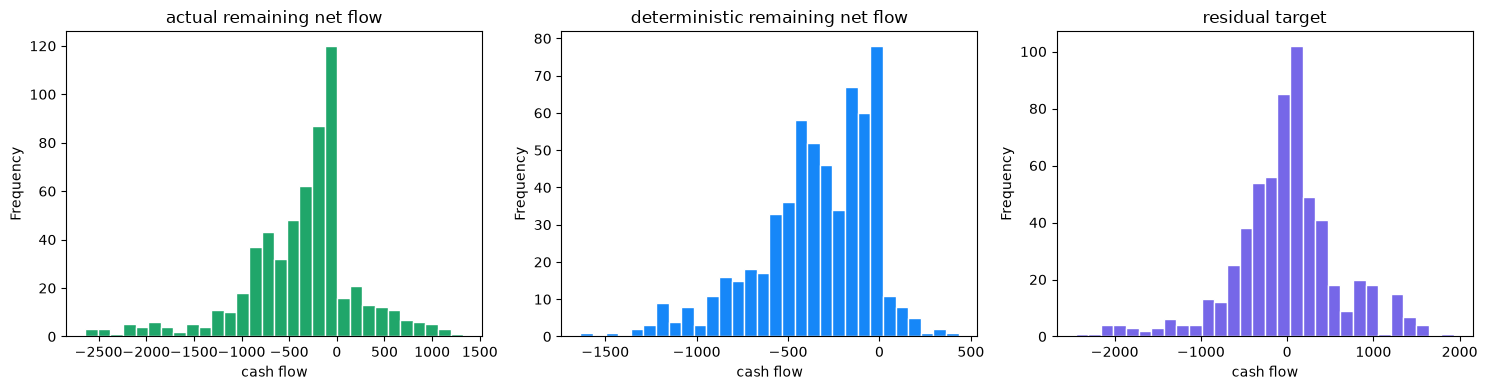

In [10]:
plot_columns = [
    'actual_remaining_net_flow',
    'deterministic_remaining_net_flow',
    'residual_target',
]
plot_frame = processed_frame[plot_columns].map(float)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ['#20A66A', '#1687F8', '#7667E8']
for column, axis, color in zip(plot_columns, axes, colors):
    plot_frame[column].plot.hist(bins=30, ax=axis, color=color, edgecolor='white')
    axis.set_title(column.replace('_', ' '))
    axis.set_xlabel('cash flow')
fig.tight_layout()
plt.show()

## 4. Signalement explicite des valeurs atypiques

La règle IQR ci-dessous sert uniquement à l'inspection. Elle ne supprime et ne transforme aucune observation.

In [11]:
residuals = plot_frame['residual_target']
q1, q3 = residuals.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (residuals < lower_bound) | (residuals > upper_bound)
print({'lower_bound': lower_bound, 'upper_bound': upper_bound, 'flagged_rows': int(outlier_mask.sum())})
display(processed_frame.loc[outlier_mask, [
    'profile_key', 'currency', 'target_month', 'cutoff_date',
    'actual_remaining_net_flow', 'deterministic_remaining_net_flow', 'residual_target'
]].head(25))

{'lower_bound': -1202.1867500000003, 'upper_bound': 1129.75005, 'flagged_rows': 54}


,profile_key,currency,target_month,cutoff_date,actual_remaining_net_flow,deterministic_remaining_net_flow,residual_target
5,profile_0001,TND,2024-02,2024-02-05,549.7000,-608.5500,1158.2500
20,profile_0001,TND,2024-05,2024-05-05,-1394.6900,-126.1875,-1268.5025
61,profile_0001,TND,2025-01,2025-01-10,808.7300,-512.6216,1321.3516
71,profile_0001,TND,2025-03,2025-03-10,-2240.2900,-511.5100,-1728.7800
72,profile_0001,TND,2025-03,2025-03-15,-2080.7100,-519.8183,-1560.8917
73,profile_0001,TND,2025-03,2025-03-20,-2026.0200,-219.2250,-1806.7950
74,profile_0001,TND,2025-03,2025-03-25,-1940.0100,-30.0983,-1909.9117
80,profile_0001,TND,2025-05,2025-05-05,490.0200,-754.4550,1244.4750
81,profile_0001,TND,2025-05,2025-05-10,581.3300,-698.7200,1280.0500
82,profile_0001,TND,2025-05,2025-05-15,857.7700,-678.3917,1536.1617


## Mes décisions — à compléter après l'audit

- TODO : caractéristiques retenues et justification de chacune.
- TODO : stratégie de séparation temporelle et par profil pour entraînement/validation/test.
- TODO : métriques et analyses par devise et niveau de fallback.
- TODO : interprétation des valeurs atypiques (événements valides ou défauts de données).
- TODO : familles de modèles à tester ultérieurement.
- TODO : versionnement de la configuration, du dataset, des résultats et des futurs artefacts.

**Arrêt volontaire : aucun modèle n'est entraîné dans ce notebook.**

In [12]:
date_audit = raw_frame.copy()
date_audit["booking_date"] = pd.to_datetime(date_audit["booking_date"])
date_audit["known_date"] = pd.to_datetime(date_audit["known_date"])
date_audit["visibility_delay_days"] = (
    date_audit["known_date"] - date_audit["booking_date"]
).dt.days

display(
    date_audit["visibility_delay_days"]
    .describe()
    .rename("value")
    .to_frame()
)

print("Late-arriving rows:", int((date_audit["visibility_delay_days"] > 0).sum()))
print("Invalid negative delays:", int((date_audit["visibility_delay_days"] < 0).sum()))

display(
    date_audit["visibility_delay_days"]
    .value_counts()
    .sort_index()
    .rename("rows")
    .to_frame()
)

,value
count,1642.000000
mean,0.643727
std,0.745729
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,2.000000


Late-arriving rows: 789
Invalid negative delays: 0


,rows
visibility_delay_days,
0,853
1,521
2,268


In [13]:
evaluation = processed_frame.copy()

for column in [
    "actual_remaining_net_flow",
    "deterministic_remaining_net_flow",
    "residual_target",
]:
    evaluation[column] = evaluation[column].map(float)

naive_mae = evaluation["actual_remaining_net_flow"].abs().mean()
deterministic_mae = evaluation["residual_target"].abs().mean()

summary = pd.Series({
    "naive_zero_remaining_flow_mae": naive_mae,
    "deterministic_forecast_mae": deterministic_mae,
    "deterministic_improvement_percent": (
        100 * (1 - deterministic_mae / naive_mae)
        if naive_mae != 0 else float("nan")
    ),
    "residual_mean": evaluation["residual_target"].mean(),
    "residual_median": evaluation["residual_target"].median(),
    "residual_standard_deviation": evaluation["residual_target"].std(),
})

display(summary.to_frame("value"))

,value
naive_zero_remaining_flow_mae,500.755167
deterministic_forecast_mae,437.657124
deterministic_improvement_percent,12.600577
residual_mean,-14.024572
residual_median,15.235800
residual_standard_deviation,624.592007


In [14]:
cutoff_results = []

for cutoff_day, group in evaluation.groupby("cutoff_day"):
    cutoff_results.append({
        "cutoff_day": cutoff_day,
        "rows": len(group),
        "naive_mae": group["actual_remaining_net_flow"].abs().mean(),
        "deterministic_mae": group["residual_target"].abs().mean(),
        "residual_median": group["residual_target"].median(),
        "residual_rmse": (
            group["residual_target"].pow(2).mean() ** 0.5
        ),
    })

display(pd.DataFrame(cutoff_results).set_index("cutoff_day"))

,rows,naive_mae,deterministic_mae,residual_median,residual_rmse
cutoff_day,,,,,
5,120,759.981000,648.018601,52.88050,799.214099
10,120,738.917167,609.069127,-41.00350,776.574129
15,120,556.302500,485.164425,4.78400,645.989679
20,120,330.786417,307.410003,-4.09665,460.561554
25,120,117.788750,138.623466,25.20790,277.629600


In [ ]:
Conclusions to put in the notebook

You can replace the TODOs with:

The deterministic baseline improves overall MAE by 12.60%, confirming that historical remaining cash flow contains useful predictive information.
Residual mean and median are close to zero, indicating limited systematic bias.
Large differences between MAE and RMSE confirm the presence of financial shocks and heavy-tailed errors.
Performance differs considerably by cutoff day.
The deterministic baseline is useful from days 5–20 but degrades performance at day 25.
Cutoff day and days remaining must be included as model features.
Outliers will remain in the dataset because they represent plausible financial events.
All rows belonging to one profile-month must stay in the same temporal partition.
Models will be selected using validation data only; the test period will remain untouched until final evaluation.